# Evaluation-held-out public friendship networks
This is a new **post-collection structural-transfer benchmark**, not a change to the locked 24 primary tests. It uses only the 896 original attempts (890 valid); all six supplemental graphs stay excluded.
The new public networks were excluded from baseline fitting, not necessarily from LLM pretraining. The fixed generated rosters cannot predict named people or validate national/cultural behavior. Two source studies and overlapping subgraphs do not supply hundreds of independent human samples.

**Revision 4:** target-density efficiency diagnostic, clustering margins, record-level heterogeneity, paired residual ranges and a matched-size sensitivity diagnostic. The original 50-node benchmark is unchanged.

In [1]:
from pathlib import Path
import json, hashlib, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'analysis_heldout/protocol.json').is_file())
sys.path.insert(0, str(ROOT))
OUT = ROOT/'outputs/heldout_evaluation/20261105_v1'
seal = json.loads((OUT/'evaluation_manifest.json').read_text())
assert seal['status'] == 'COMPLETE_HELDOUT_STRUCTURAL_EVALUATION_WITH_CAVEATS'
assert seal['supplemental_graphs'] == seal['paid_calls'] == seal['ledger_queries'] == 0
for name, record in seal['artifacts'].items():
    path = OUT/name
    assert path.stat().st_size == record['bytes'] and hashlib.sha256(path.read_bytes()).hexdigest() == record['sha256'], name
for name, expected in seal['code_sha256'].items():
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest() == expected, name
assert hashlib.sha256((ROOT/'outputs/primary_analysis/20261105/evaluation_manifest.json').read_bytes()).hexdigest() == seal['previous_primary_seal_sha256']
from analysis_primary.core import load_inputs
_, primary, _ = load_inputs(ROOT)
candidate = pd.read_csv(OUT/'candidate_metrics.csv')
original = candidate[candidate.kind.eq('LLM')]
assert len(original) == 896 and original.valid.sum() == 890
assert set(original.run_id) == set(primary.original_run_id)
print('Primary-only cohort and all benchmark artifact/code hashes verified.')

from analysis_figures.deep_review import show, table


Primary-only cohort and all benchmark artifact/code hashes verified.


## Public data and sampling
SNAP supplies ten Facebook alter graphs: keep roster nodes from .feat files, ignore all feature values, and exclude the ego. Reciprocal edge-list rows become one simple edge. Some alter rosters include isolates.
The SocioPatterns survey becomes one observed-roster graph of positive-reporting nominators, restricted to nominations between those roster members, then OR-projected. This cannot recover zero-nominating/nonresponding people; missing survey reports are not fabricated as zero-tie observations. No sensor/contact graph is substituted for friendship.
Take 32 deterministic uniform induced 50-node draws per cohort, retaining isolates, empty and disconnected outcomes. These draws overlap. The ten Facebook records also overlap with each other. Cohort/source summaries are descriptive, without independent-sample CIs. See source attribution/license notes in docs/HELDOUT_REAL_WORLD_EVALUATION.md.

In [2]:
quality = pd.read_csv(OUT/'dataset_quality.csv')
overlap = pd.read_csv(OUT/'cohort_overlap.csv')
display(quality[['source','cohort','observed_roster_nodes','observed_edges','observed_isolates','dropped_external_nominations']])
print('Facebook cohort pairs sharing observed nodes:', int(overlap.shared_nodes.gt(0).sum()), '/', len(overlap))
display(json.loads((OUT/'development_fit.json').read_text()))


,source,cohort,observed_roster_nodes,observed_edges,observed_isolates,dropped_external_nominations
0,snap_facebook,FB01,347,2519,14,0
1,snap_facebook,FB02,1045,26749,11,0
2,snap_facebook,FB03,227,3192,3,0
3,snap_facebook,FB04,159,1693,9,0
4,snap_facebook,FB05,170,1656,2,0
5,snap_facebook,FB06,66,270,5,0
6,snap_facebook,FB07,792,14024,6,0
7,snap_facebook,FB08,755,30025,8,0
8,snap_facebook,FB09,547,4813,13,0
9,snap_facebook,FB10,59,146,7,0


Facebook cohort pairs sharing observed nodes: 22 / 45


{'BA_m': 5,
 'ER_p': 0.18893569470401766,
 'WS_grid': [{'mean_clustering': 0.666666666666667,
   'p': 0.0,
   'squared_error': 0.04664737669117011},
  {'mean_clustering': 0.5892531080031083,
   'p': 0.05,
   'squared_error': 0.01920066911658347},
  {'mean_clustering': 0.5220277951215451,
   'p': 0.1,
   'squared_error': 0.005089561990411203},
  {'mean_clustering': 0.40160487949550444,
   'p': 0.2,
   'squared_error': 0.0024090181297235754},
  {'mean_clustering': 0.26219218766323543,
   'p': 0.4,
   'squared_error': 0.035530154396814874},
  {'mean_clustering': 0.20467304321280716,
   'p': 0.6,
   'squared_error': 0.06052268436832222},
  {'mean_clustering': 0.19136816308691307,
   'p': 0.8,
   'squared_error': 0.06724606673869292},
  {'mean_clustering': 0.1888649637417536,
   'p': 1.0,
   'squared_error': 0.06855058437353768}],
 'WS_k': 10,
 'WS_p': 0.2,
 'clustering_target': 0.45068662895213624,
 'density_target': 0.18893569470401766,
 'development_communities': 7,
 'development_records

## Baselines and distance meaning
Fit ER density, BA attachment count, and WS neighborhood/rewiring only on the old eight-network panel; average the two Tailor waves first so seven communities have equal weight. Each baseline has eight independent Monte Carlo banks of 56 synthetic 50-node graphs. All new source graphs are excluded from fitting.
Wasserstein-1 compares distributions of each bounded graph-level metric separately. Within every frozen method/model group, weight the seven instruction conditions equally, dividing each condition's 1/7 among its valid outcomes. Failures stay recorded but are not zero-filled; distances are conditional on success. Baseline banks and target node draws have uniform weights.
Average cohort distances equally within each source. The bank min/max range is Monte Carlo sensitivity, **not a confidence interval**. Do not optimize or interpret a composite winner. G(n,m) and degree-preserving controls use target information and never enter the transfer ranking.

In [3]:
targets = pd.read_csv(OUT/'heldout_sample_metrics.csv')
distances = pd.read_csv(OUT/'per_cohort_distances.csv')
def ecdf_w1(left, right, weights):
    order = np.argsort(left)
    x = np.asarray(left)[order]
    cumulative = np.r_[0., np.cumsum(np.asarray(weights)[order]) / np.sum(weights)]
    y = np.sort(np.asarray(right))
    grid = np.unique(np.r_[x, y])
    fx = cumulative[np.searchsorted(x, grid[:-1], side='right')]
    fy = np.searchsorted(y, grid[:-1], side='right') / len(y)
    return float(np.sum(np.diff(grid) * np.abs(fx-fy)))
maximum_error = 0.
for row in distances.itertuples():
    group = candidate[candidate.candidate.eq(row.candidate) & candidate.bank.eq(row.bank)]
    valid = group[group.valid & group[row.metric].notna()]
    if row.kind == 'LLM':
        counts = valid.condition.value_counts()
        assert len(counts) == 7
        weights = valid.condition.map(lambda c: 1./(7*counts[c])).to_numpy()
    else:
        weights = np.ones(len(valid))/len(valid)
    human = targets[targets.source.eq(row.source) & targets.cohort.eq(row.cohort)]
    maximum_error = max(maximum_error, abs(ecdf_w1(valid[row.metric].to_numpy(), human[row.metric].to_numpy(), weights)-row.w1))
assert maximum_error < 1e-12
print('Independent ECDF integration checked', len(distances), 'distances; max error =', maximum_error)
summary = pd.read_csv(OUT/'source_distance_summary.csv')
display(summary)


Independent ECDF integration checked 2640 distances; max error = 1.1102230246251565e-15


,source,candidate,kind,metric,mean_w1,min_bank_w1,max_bank_w1,banks
0,snap_facebook,Baseline:BA,baseline,avg_clustering_coef,0.145449,0.144410,0.146381,8
1,snap_facebook,Baseline:BA,baseline,degree_gini,0.211804,0.210022,0.213534,8
2,snap_facebook,Baseline:BA,baseline,density,0.097230,0.097230,0.097230,8
3,snap_facebook,Baseline:BA,baseline,global_efficiency,0.363322,0.362871,0.363691,8
4,snap_facebook,Baseline:BA,baseline,prop_nodes_lcc,0.422438,0.422438,0.422438,8
...,...,...,...,...,...,...,...,...
223,sociopatterns_friendship,LLM:sequential:gpt-6-sol,LLM,degree_gini,0.129073,0.129073,0.129073,1
224,sociopatterns_friendship,LLM:sequential:gpt-6-sol,LLM,density,0.115835,0.115835,0.115835,1
225,sociopatterns_friendship,LLM:sequential:gpt-6-sol,LLM,global_efficiency,0.402825,0.402825,0.402825,1
226,sociopatterns_friendship,LLM:sequential:gpt-6-sol,LLM,prop_nodes_lcc,0.580000,0.580000,0.580000,1


## Conditional controls: not transfer baselines
Each held-out sample has eight G(n,m) controls and eight finite degree-swap controls. Degree swaps preserve the exact roster, degree sequence and edge count; 10m swaps do not establish uniform mixing. A target/control residual is defined only if all eight succeed, and a cohort summary only if all 32 targets are complete. No failed control is silently zero-filled or given extra weight.
These checks ask how much observed clustering/closure remains after conditioning on density or degrees. They do not validate LLM realism and are not null p-values.

In [4]:
controls = pd.read_csv(OUT/'conditional_control_metrics.csv')
joined = controls.merge(targets[['source','cohort','draw','density','degree_gini']], on=['source','cohort','draw'], suffixes=('', '_target'), validate='many_to_one')
assert np.allclose(joined.loc[joined.success,'density'], joined.loc[joined.success,'density_target'], atol=1e-12, rtol=0)
degree = joined.control.eq('degree_swap') & joined.success
assert np.allclose(joined.loc[degree,'degree_gini'], joined.loc[degree,'degree_gini_target'], atol=1e-12, rtol=0)
print('Conditional draws:', len(controls), '| failed:', int((~controls.success).sum()))
display(pd.read_csv(OUT/'conditional_residuals.csv'))


Conditional draws: 5632 | failed: 0


,source,cohort,control,metric,target_draws,complete_target_draws,failed_control_draws,mean_target_minus_control,status
0,snap_facebook,FB01,Gnm,density,32,32,0,0.000000,complete_descriptive
1,snap_facebook,FB01,Gnm,avg_clustering_coef,32,32,0,0.218685,complete_descriptive
2,snap_facebook,FB01,Gnm,global_efficiency,32,32,0,-0.093708,complete_descriptive
3,snap_facebook,FB01,Gnm,transitivity,32,32,0,0.374928,complete_descriptive
4,snap_facebook,FB01,Gnm,degree_gini,32,32,0,0.218079,complete_descriptive
...,...,...,...,...,...,...,...,...,...
127,sociopatterns_friendship,School2013,degree_swap,avg_clustering_coef,32,32,0,0.277102,complete_descriptive
128,sociopatterns_friendship,School2013,degree_swap,global_efficiency,32,32,0,-0.120298,complete_descriptive
129,sociopatterns_friendship,School2013,degree_swap,transitivity,32,32,0,0.404428,complete_descriptive
130,sociopatterns_friendship,School2013,degree_swap,degree_gini,32,32,0,0.000000,complete_descriptive


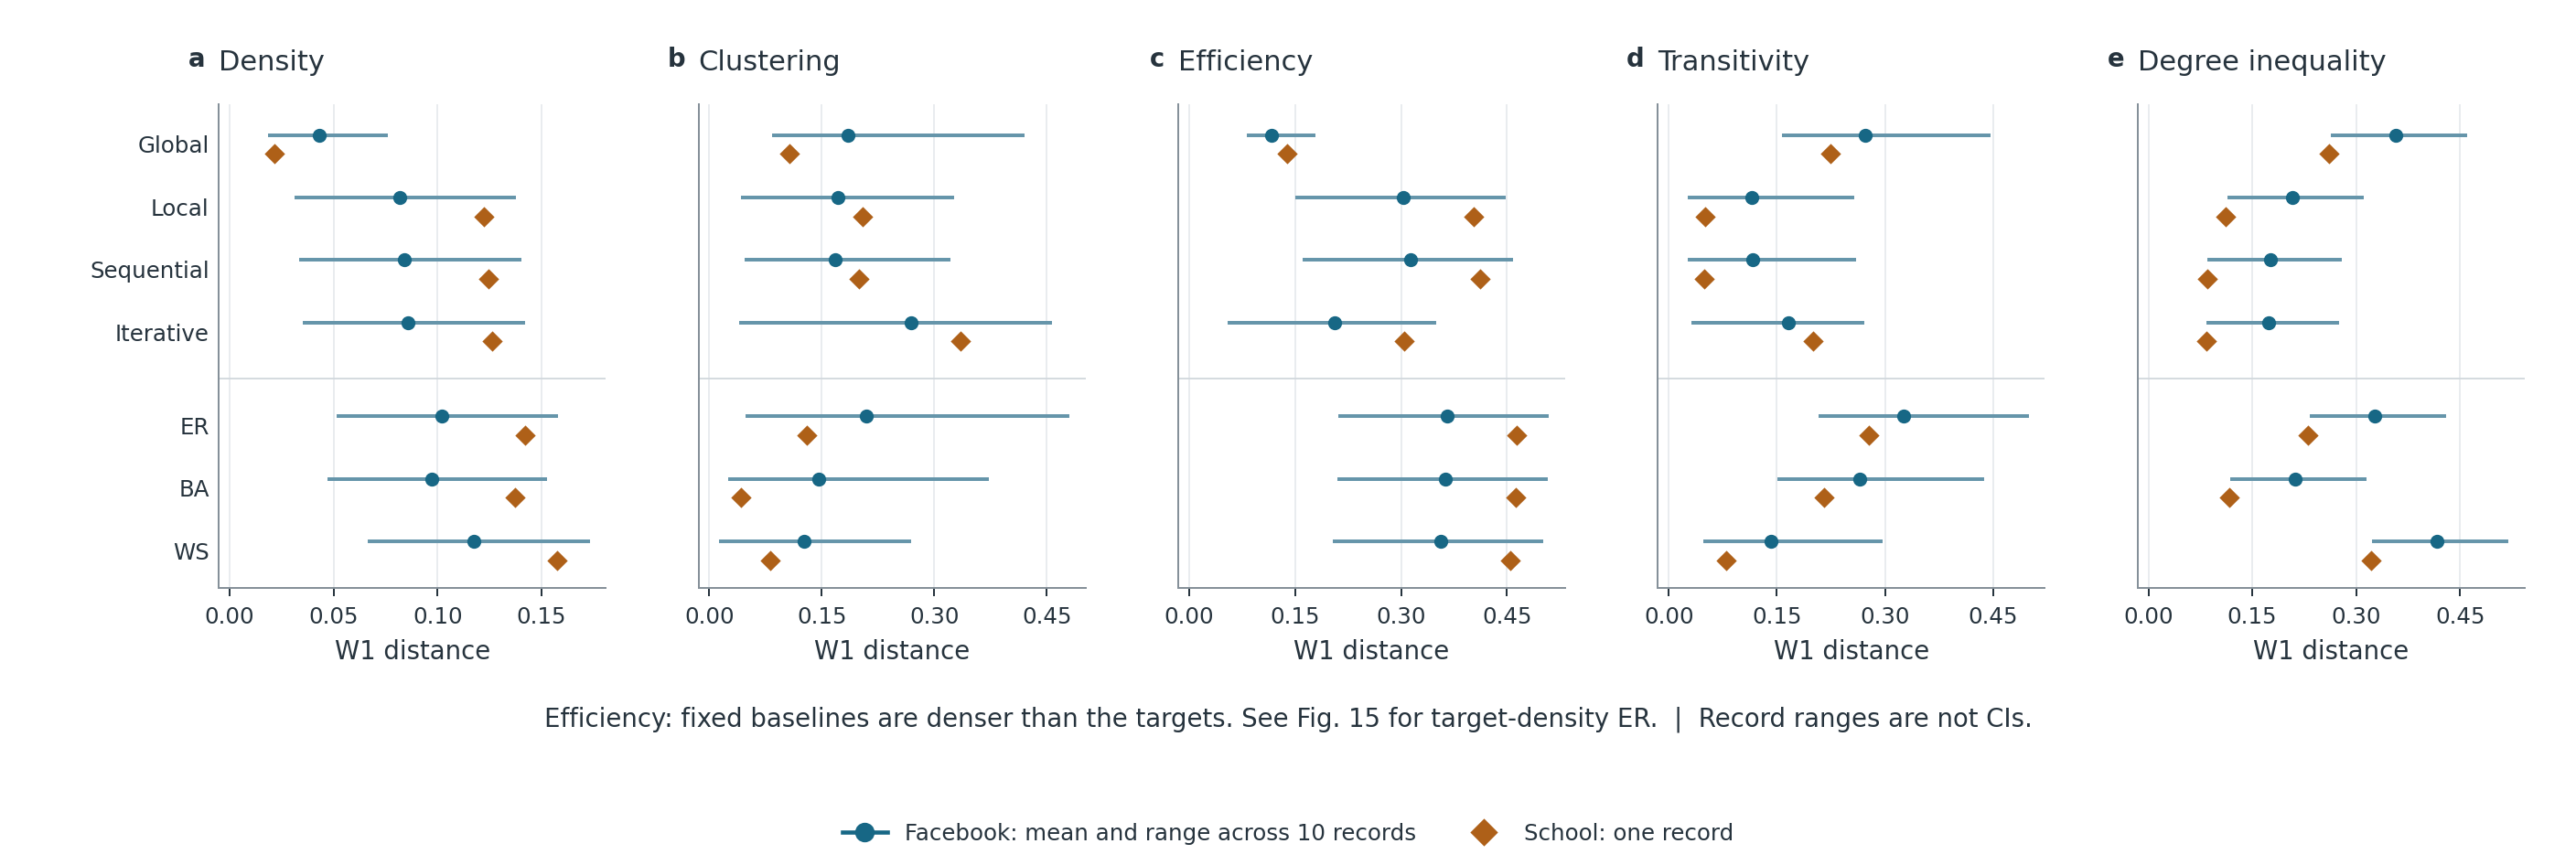

Lower W1 is closer on one metric. Blue spans are record ranges, not confidence intervals. Substantial overlap and small rank margins preclude an overall winner. All three baseline settings were fixed on development data. See figure 15 for the separate target-informed efficiency diagnostic.

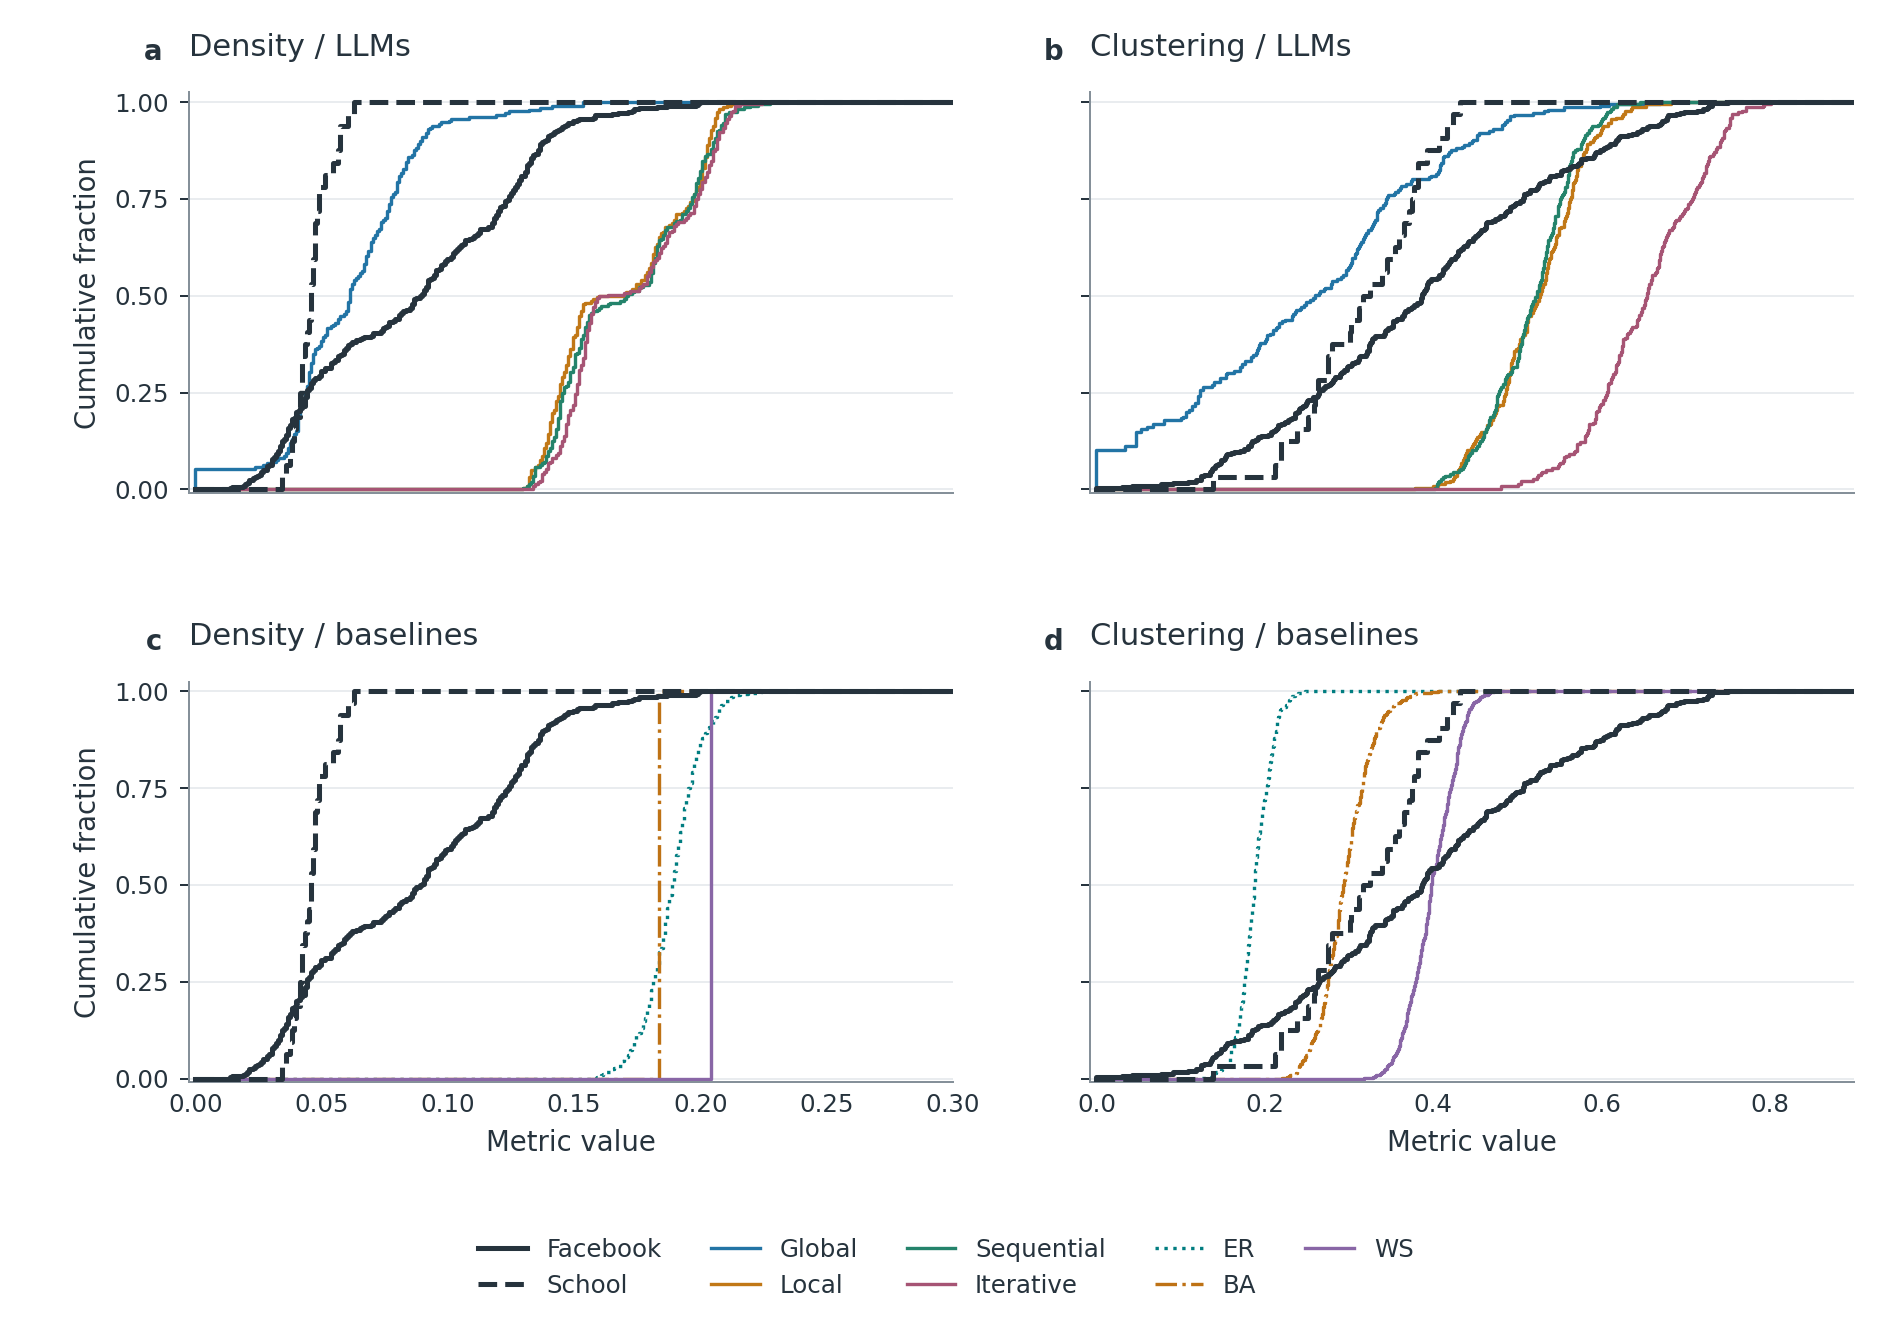

Height is the fraction of networks at or below the value. Compare each generated curve with both observed sources: Facebook (solid black, equal record weights) and school (dashed black). Candidates appear only once per metric: top panels mix the four fixed models equally within a procedure, retaining equal instruction weights; lower panels pool eight equal-size banks per baseline. The density axis covers all observed values. Pooled distributions illustrate shape; distance between these curves is NOT the cohort-wise score in figure 08.

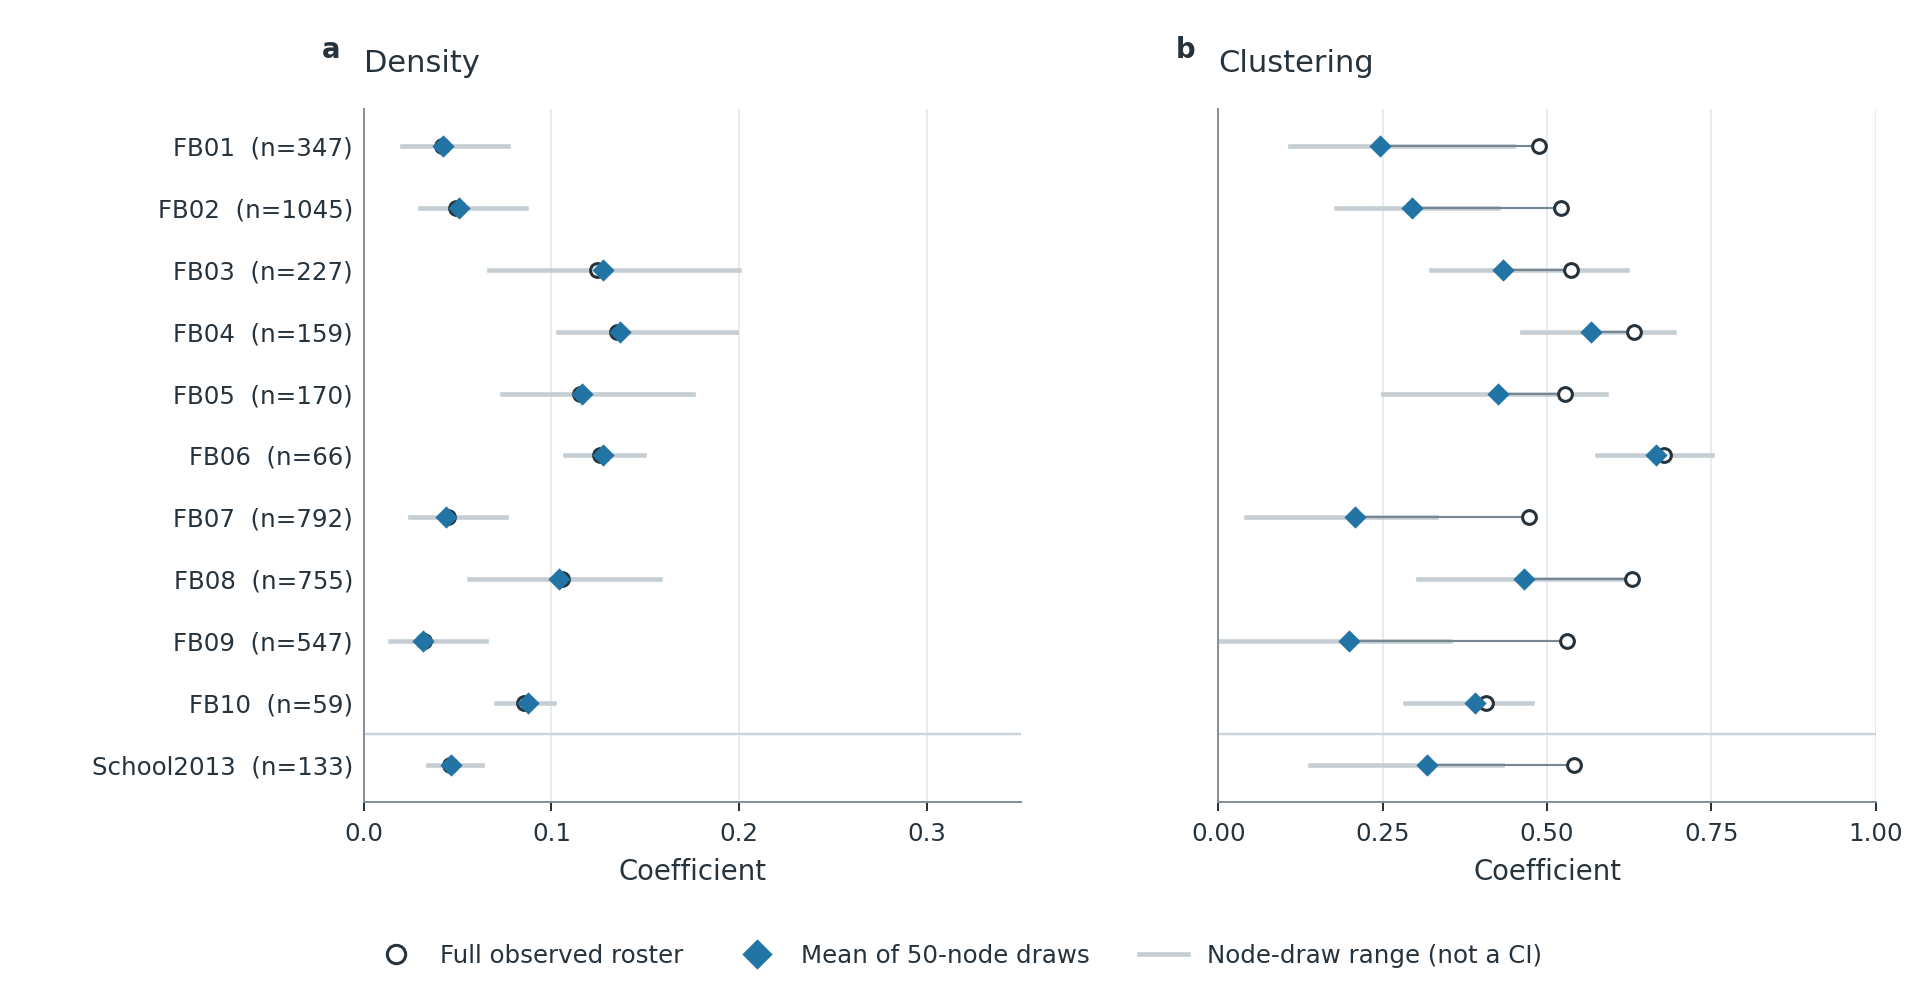

**Sampling changes the reference.** Open circles show the full observable
roster; diamonds show the average over 32 induced 50-node draws. Light spans
are minima/maxima of those draws, NOT CIs. Lines join full and sampled means
for the same record. The observable school roster excludes unrecoverable
nonresponders; Facebook cohorts and within-cohort samples overlap.

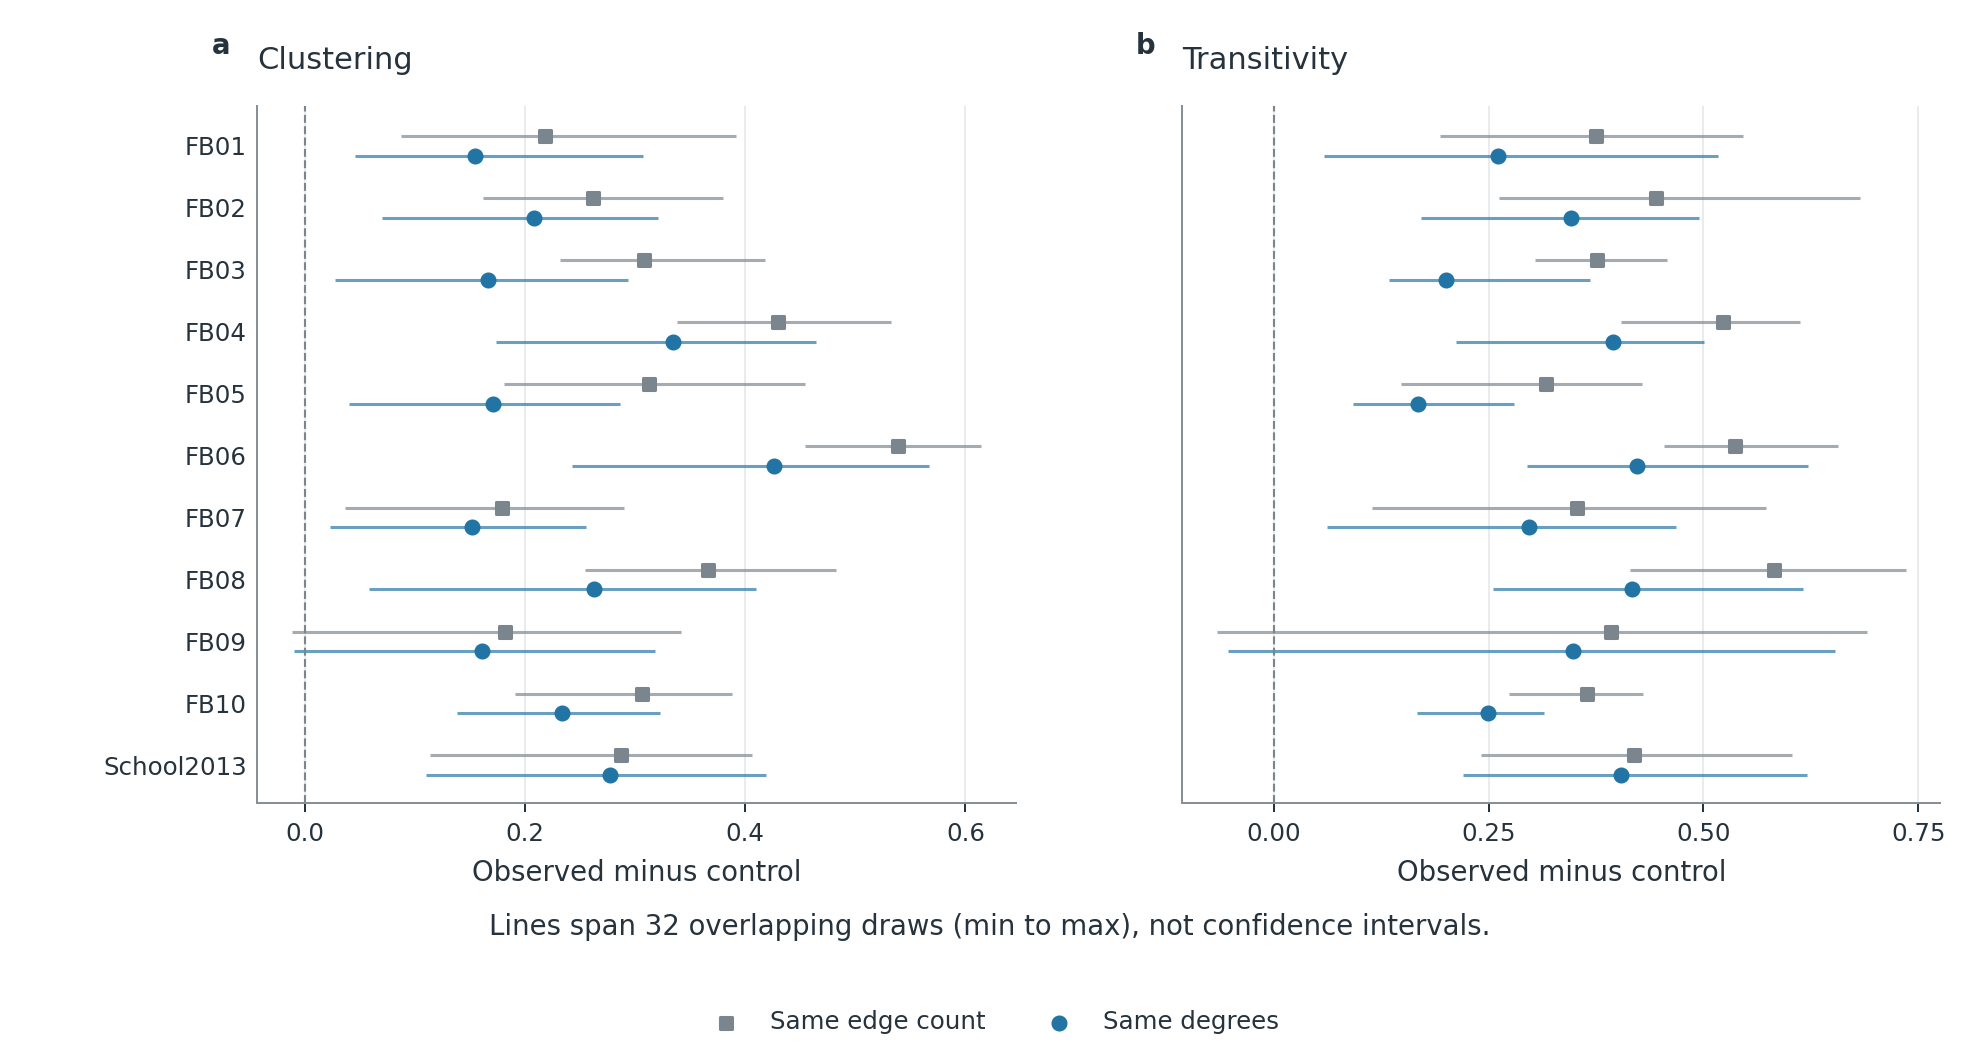

Means and full ranges of 32 paired target-minus-control values per record, not confidence intervals. The two controls preserve different properties of the observed graphs.

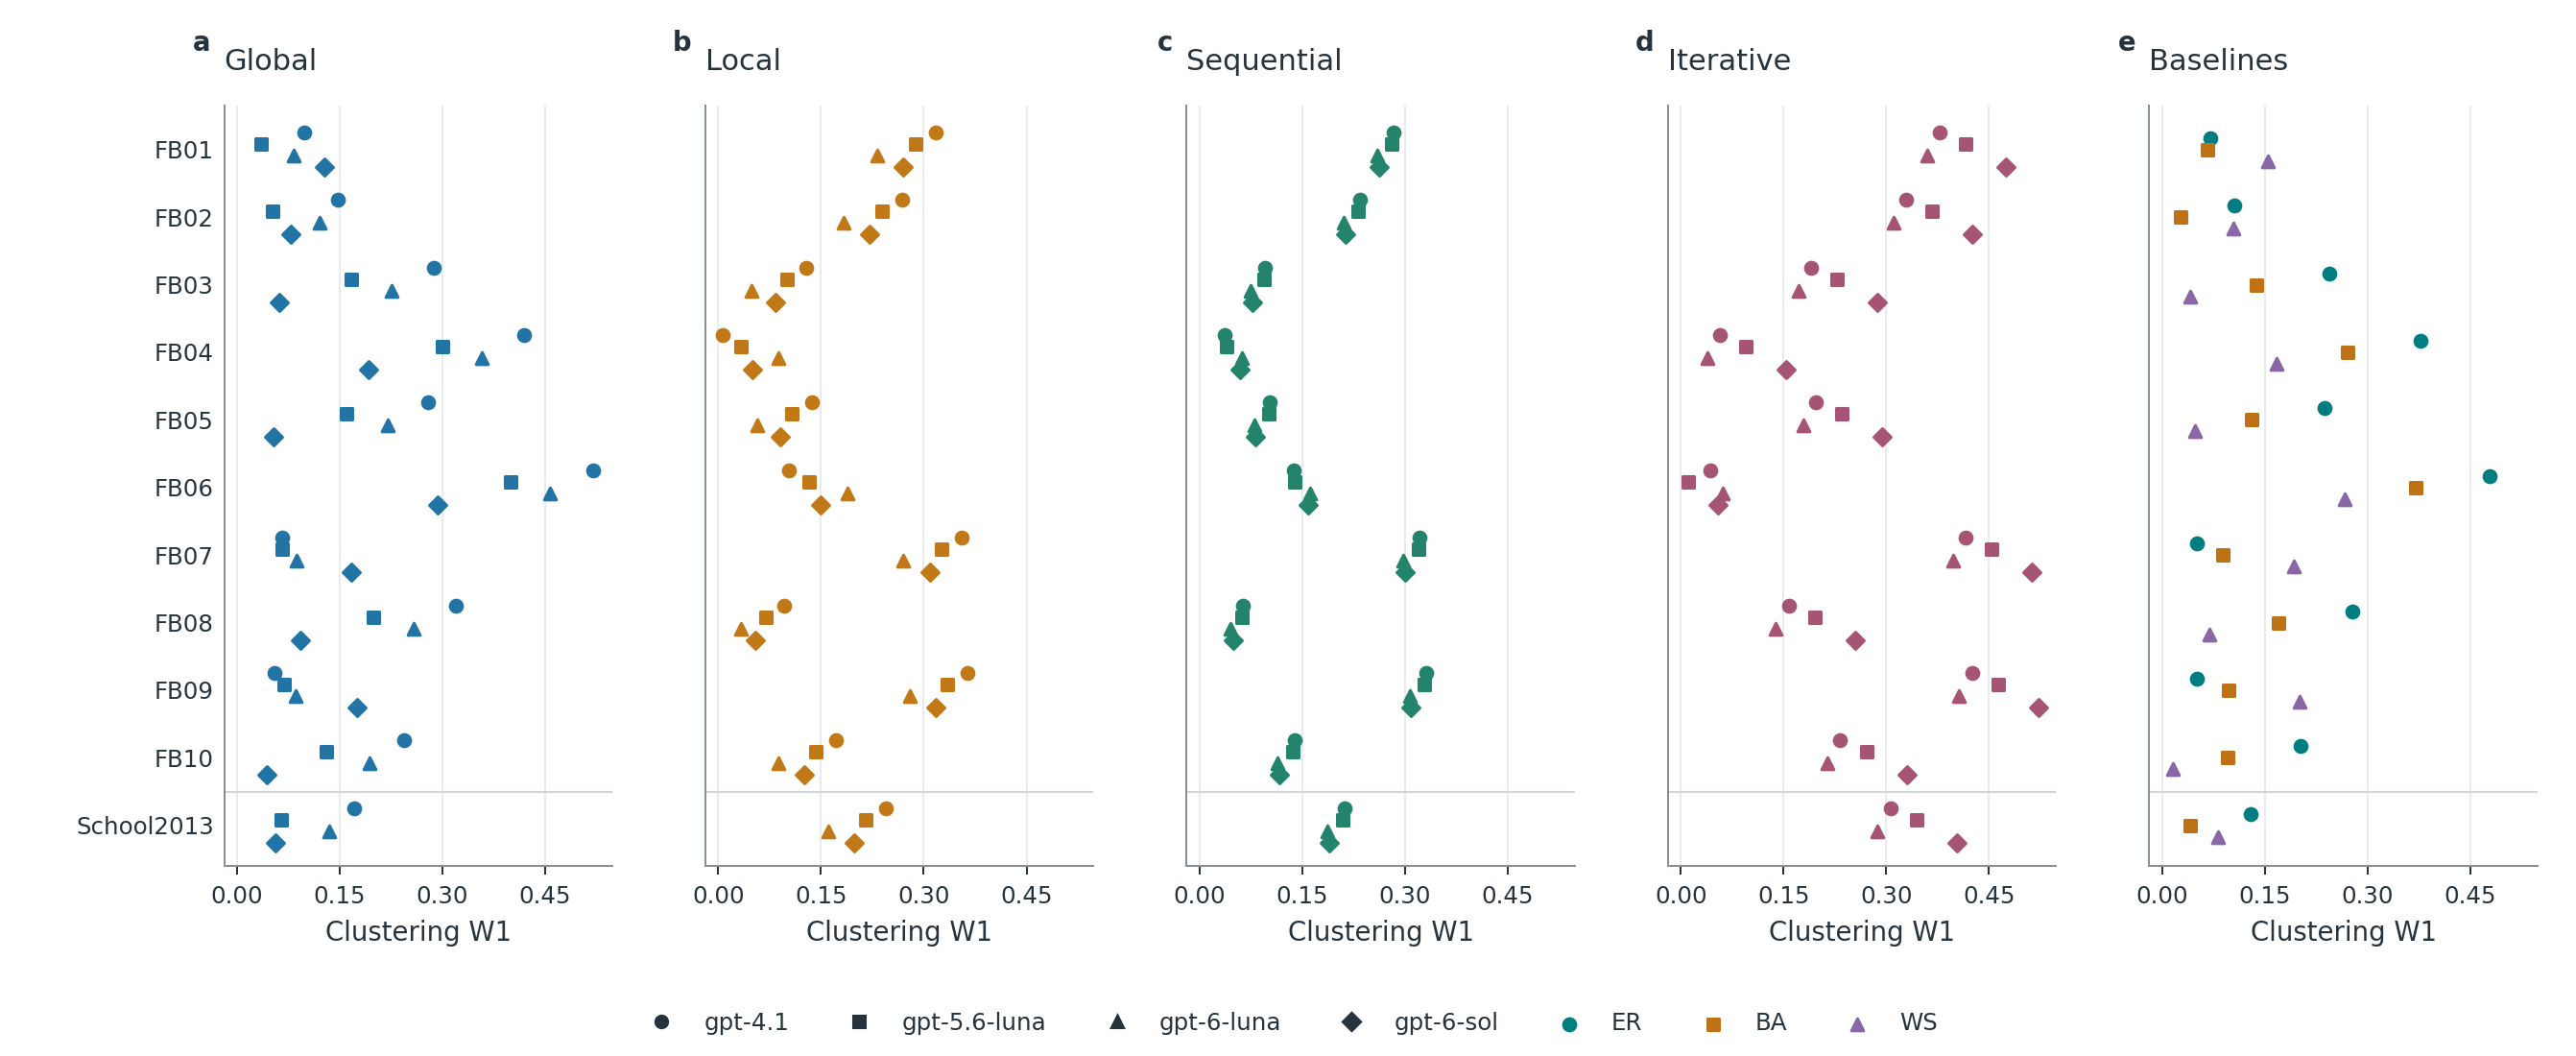

Each row is one observed record. Panels share one clustering W1 scale. Four fixed models per LLM procedure remain separate, and the last panel shows each classical baseline averaged over its eight banks. These 19 candidates show variability hidden by procedure means. Rows are not independent population replicates.

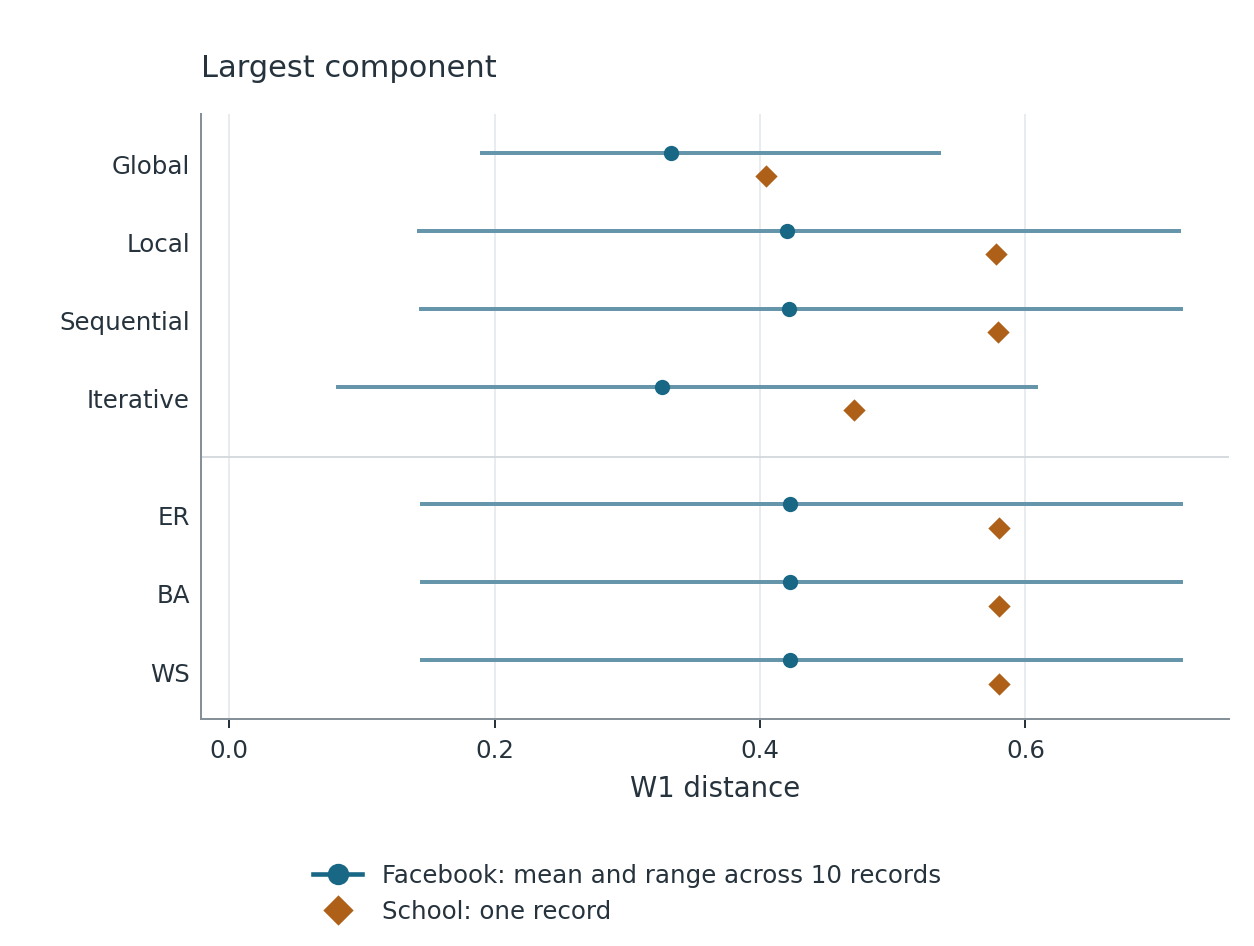

Appendix: largest-component fraction, with the same record-level W1 averaging and descriptive ranges as figure 08. 447/448 ER graphs and 448/448 BA and WS graphs are connected. Distances can nearly coincide without being exactly identical; this metric is retained, not deleted.

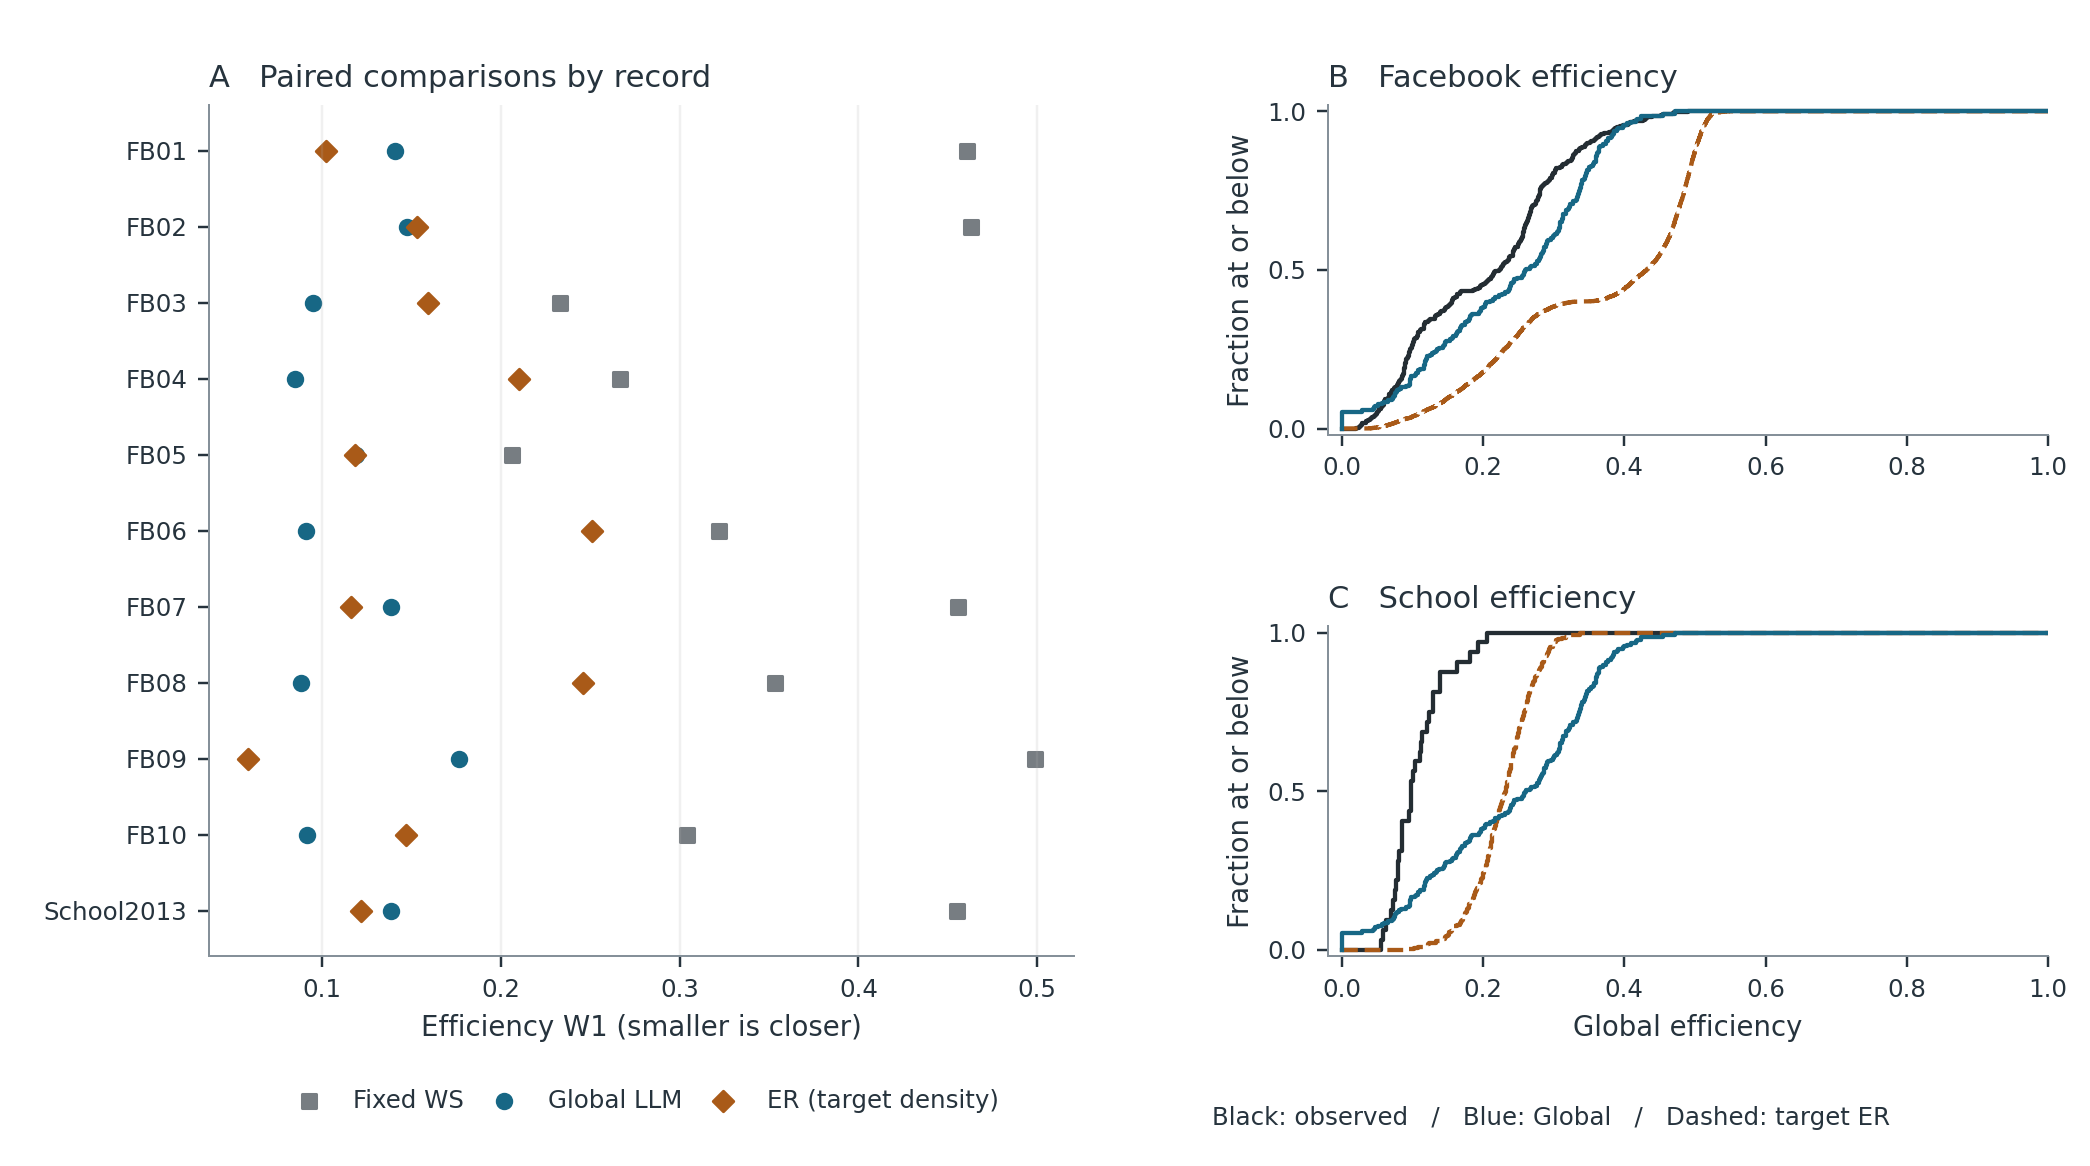

At 50 nodes the post-hoc ER diagnostic uses the FULL observed density of each record, unavailable to transfer competitors. Left: W1 per record (mean of bank or model distances). Right: illustrative distributions, not the left-panel W1. Facebook records receive equal weight within source. Unreachable pairs contribute zero to efficiency.

In [5]:
show(ROOT, ['08_heldout_distances', '09_heldout_distributions', '10_sampling_effect', '11_conditional_controls', '12_cohort_sensitivity', '13_appendix_lcc', '15_efficiency_density'])


## Does the clustering comparison survive a smaller roster?
This post-hoc diagnostic uses nested, uniformly selected 25-, 40- and 50-node subsets of **both** observed and generated graphs, with fixed baseline parameters. Each cell below is mean clustering W1 (lower is closer); columns are not independent samples. One ordering per parent graph is not a sample of native small-network generation. A separate US-English-only check at 50 nodes is not a geographic match: the school survey is French, and SNAP does not establish a representative US population.

In [6]:
from analysis_figures.publication_v3 import OUTPUT as REVIEW_OUTPUT
release = ROOT / REVIEW_OUTPUT
receipt = json.loads((release / 'figure_manifest.json').read_text())
scores_path = release / 'sensitivity_source_summary.csv'
assert receipt['status'] == 'COMPLETE_REVIEW_V3'
assert hashlib.sha256(scores_path.read_bytes()).hexdigest() == receipt['artifacts'][scores_path.name]
size_scores = pd.read_csv(scores_path)
cluster = size_scores[size_scores.metric.eq('avg_clustering_coef')]
display(cluster[cluster.scope.eq('original weighting')].pivot(index='procedure', columns=['source','n'], values='mean').round(4))
display(cluster[cluster.scope.eq('US-English only')].pivot(index='procedure', columns='source', values='mean').round(4))
display(table(ROOT,'clustering_margins'))
display(table(ROOT,'efficiency_summary'))

source,snap_facebook,sociopatterns_friendship,snap_facebook,sociopatterns_friendship,snap_facebook,sociopatterns_friendship
n,25,25,40,40,50,50
procedure,,,,,,
BA,0.1249,0.1297,0.1389,0.0449,0.1454,0.0416
ER,0.1524,0.0456,0.1865,0.0844,0.2094,0.1298
WS,0.1602,0.2499,0.1352,0.1345,0.1259,0.0813
global,0.1737,0.0627,0.1847,0.0958,0.1847,0.1067
iterative,0.3204,0.4424,0.2884,0.3768,0.2687,0.3347
local,0.1881,0.2953,0.1809,0.2423,0.1716,0.2045
sequential,0.1795,0.2846,0.1738,0.2311,0.1678,0.1991


source,snap_facebook,sociopatterns_friendship
procedure,,
BA,0.1454,0.0416
ER,0.2094,0.1298
WS,0.1259,0.0813
global,0.1983,0.1152
iterative,0.2845,0.3533
local,0.1771,0.2110
sequential,0.1712,0.2044


,n,source,closest,w1,runner_up,runner_up_w1,margin
0,25,snap_facebook,BA,0.124898,ER,0.152358,0.027460
1,25,sociopatterns_friendship,ER,0.045558,global,0.062697,0.017139
2,40,snap_facebook,WS,0.135195,BA,0.138908,0.003714
3,40,sociopatterns_friendship,BA,0.044864,ER,0.084410,0.039546
4,50,snap_facebook,WS,0.125871,BA,0.145449,0.019578
5,50,sociopatterns_friendship,BA,0.041572,WS,0.081304,0.039732


,source,records,global,ER,WS,target_ER,ws_gap_closed,target_strictly_closer,target_closer_or_within_015
0,snap_facebook,10,0.117320,0.364785,0.356299,0.156173,0.837419,4,5
1,sociopatterns_friendship,1,0.138268,0.463440,0.454955,0.121477,1.053022,1,1
2,all_equal_record,11,0.119224,0.373753,0.365267,0.153019,0.862647,5,6


## What the comparisons support
Classical models stay competitive on clustering, but the ordering depends on which people are sampled. On Facebook at 40 nodes the WS advantage over BA is just 0.0037 W1; at school at 25 nodes ER is 0.0171 ahead of Global. These are descriptive margins, not significance or equivalence tests. Observed mean clustering exceeded degree-swap controls in all 11 records, not necessarily every draw.

**Efficiency is sensitive to edge density.** In the fixed transfer comparison Global is closer than fixed WS. Giving ER the full density of each real record changes the 11-record mean efficiency W1 to 0.153, versus 0.119 for Global and 0.365 for fixed WS. This closes 86% of that specific gap; it is not the percentage of reachability caused by density. The target-informed ER is closer than Global at school but not on average across the ten Facebook records. Figure 15 pairs each record with its own reference. The reference uses target information and is not a held-out competitor.

Facebook records share people; the school is one incomplete survey; node draws overlap. The 11-record mean weights Facebook ten times as much as school. No population or behavioral validation is implied. Supplements are excluded; the original 24-test family is unchanged.